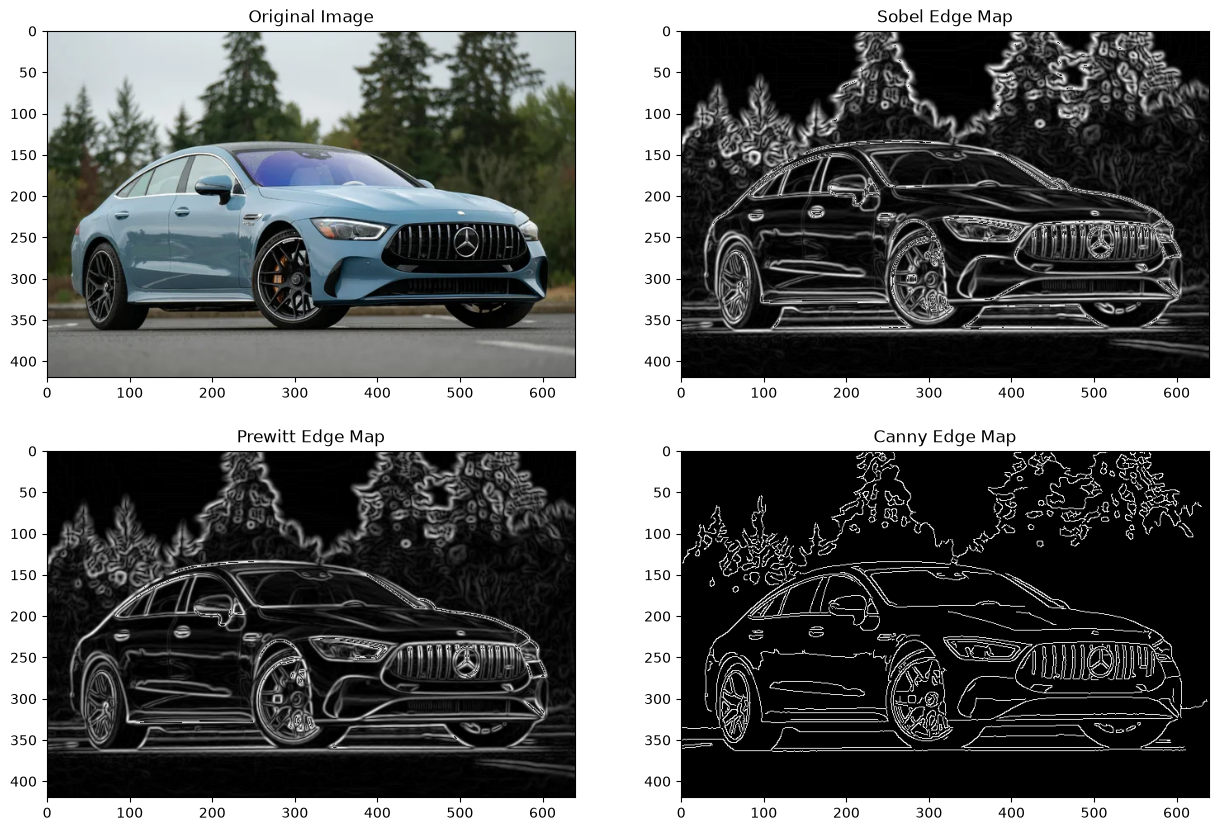

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_bgr= cv2.imread("./Mercedes Automobile.png")
img_rgb= cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
gray= cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Apply Gaussian Blur to reduce noise before edge detection
blurred= cv2.GaussianBlur(gray, (5, 5), 0)

# Sobel Edge Detector
sobelx= cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize= 3)
sobely= cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize= 3)
sobel_edges= np.uint8(np.absolute(cv2.magnitude(sobelx, sobely)))

# Prewitt Edge Detector. It uses custom kernels for X and Y derivatives
kernelx= np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]])
kernely= np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]])
prewittx= cv2.filter2D(blurred, cv2.CV_64F, kernelx)
prewitty= cv2.filter2D(blurred, cv2.CV_64F, kernely)
prewitt_edges= np.uint8(np.absolute(cv2.magnitude(prewittx, prewitty)))

# Canny Edge Detector
canny_edges= cv2.Canny(blurred, 50, 150)

# Display the original image and the three resulting edge maps
plt.figure(figsize= (15, 10))

plt.subplot(2, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")

plt.subplot(2, 2, 2)
plt.imshow(sobel_edges, cmap= "gray")
plt.title("Sobel Edge Map")

plt.subplot(2, 2, 3)
plt.imshow(prewitt_edges, cmap= "gray")
plt.title("Prewitt Edge Map")

plt.subplot(2, 2, 4)
plt.imshow(canny_edges, cmap= "gray")
plt.title("Canny Edge Map")

plt.show()

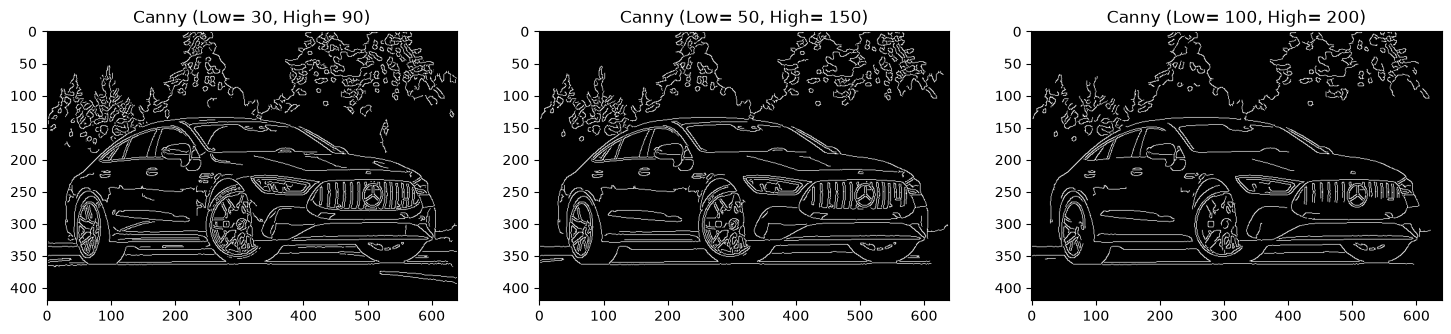

In [3]:
# Try to apply Canny edge detection using the specified threshold pairs
canny_30_90= cv2.Canny(blurred, 30, 90)
canny_50_150= cv2.Canny(blurred, 50, 150)
canny_100_200= cv2.Canny(blurred, 100, 200)

# Display the three resulting edge maps side by side
plt.figure(figsize= (18, 5))

plt.subplot(1, 3, 1)
plt.imshow(canny_30_90, cmap= "gray")
plt.title("Canny (Low= 30, High= 90)")

plt.subplot(1, 3, 2)
plt.imshow(canny_50_150, cmap= "gray")
plt.title("Canny (Low= 50, High= 150)")

plt.subplot(1, 3, 3)
plt.imshow(canny_100_200, cmap= "gray")
plt.title("Canny (Low= 100, High= 200)")

plt.show()